# Data exploration: DfT road traffic counts

This notebook explores the two DfT road traffic files and explains why we use the **London region** for Graph VPint.

**Before running:** download the two CSVs described in [`../data/README.md`](../data/README.md) into the `data/` folder.

## 1. Load the files

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

In [2]:
DATA = "../data"
BLUE = "#2a78d6"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left"})

def find(pattern, exclude=None):
    files = [f for f in sorted(glob.glob(f"{DATA}/*.csv")) if pattern in f.lower()]
    if exclude:
        files = [f for f in files if exclude not in f.lower()]
    if not files:
        raise FileNotFoundError(f"No CSV with '{pattern}' in its name found in {DATA}.")
    return files[0]

aadf = pd.read_csv(find("aadf", exclude="direction"), low_memory=False)
cp = pd.read_csv(find("count_point"), low_memory=False)
print(f"AADF: {len(aadf):,} rows, {aadf.shape[1]} columns")
print(f"Count points: {len(cp):,} rows, {cp.shape[1]} columns")

AADF: 600,551 rows, 34 columns
Count points: 46,754 rows, 19 columns


In [3]:
expected = ["count_point_id", "year", "region_name", "local_authority_name", "road_category", "road_type", "easting", "northing", "latitude", "longitude", "estimation_method", "estimation_method_detailed", "all_motor_vehicles"]
missing = [c for c in expected if c not in aadf.columns]
print("AADF columns:", aadf.columns.tolist())
print("Missing expected columns:", missing or "none")
print()
print("Count point columns:", cp.columns.tolist())

AADF columns: ['count_point_id', 'year', 'region_id', 'region_name', 'region_ons_code', 'local_authority_id', 'local_authority_name', 'local_authority_code', 'road_name', 'road_category', 'road_type', 'start_junction_road_name', 'end_junction_road_name', 'easting', 'northing', 'latitude', 'longitude', 'link_length_km', 'link_length_miles', 'estimation_method', 'estimation_method_detailed', 'pedal_cycles', 'two_wheeled_motor_vehicles', 'cars_and_taxis', 'buses_and_coaches', 'LGVs', 'HGVs_2_rigid_axle', 'HGVs_3_rigid_axle', 'HGVs_4_or_more_rigid_axle', 'HGVs_3_or_4_articulated_axle', 'HGVs_5_articulated_axle', 'HGVs_6_articulated_axle', 'all_HGVs', 'all_motor_vehicles']
Missing expected columns: none

Count point columns: ['count_point_id', 'year', 'region_id', 'region_name', 'region_ons_code', 'local_authority_id', 'local_authority_name', 'local_authority_code', 'road_name', 'road_category', 'road_type', 'start_junction_road_name', 'end_junction_road_name', 'easting', 'northing', 'latit

## 2. Count points

A count point is a fixed location on a road where traffic is counted. Each one has coordinates and road details.

Road categories: **PA** = A road, **TA** = trunk A road, **PM/TM** = motorway, **MB/MCU** = minor roads (B, C or unclassified).

In [4]:
print(f"{cp['count_point_id'].nunique():,} count points")
for col in ["road_type", "road_category", "region_name"]:
    if col in cp.columns:
        print(f"\n{col}:")
        print(cp[col].value_counts().to_string())

46,754 count points

road_type:
road_type
Minor    24785
Major    21969

road_category:
road_category
MCU    20655
PA     17676
MB      4130
TA      2824
TM      1425
PM        44

region_name:
region_name
South East                  6640
North West                  5642
East of England             5067
South West                  4738
West Midlands               4513
Yorkshire and The Humber    4006
Scotland                    3863
East Midlands               3706
London                      3665
Wales                       2661
North East                  2253


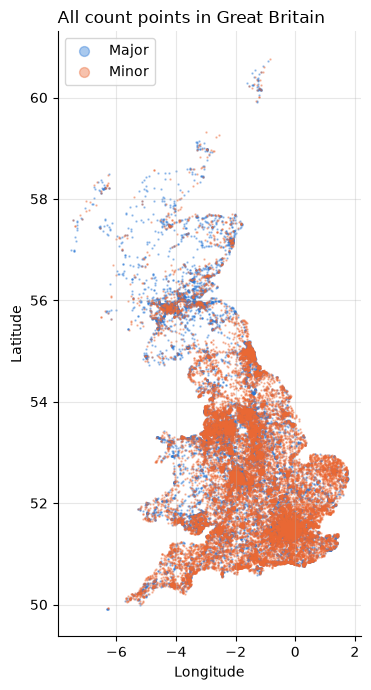

In [5]:
fig, ax = plt.subplots(figsize=(5, 7))
types = cp["road_type"].unique() if "road_type" in cp.columns else [None]
colors = {"Major": BLUE, "Minor": "#eb6834"}
for t in types:
    sub = cp if t is None else cp[cp["road_type"] == t]
    ax.scatter(sub["longitude"], sub["latitude"], s=0.5, alpha=0.4, color=colors.get(t, BLUE), label=t)
ax.set_aspect(1 / np.cos(np.radians(54)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("All count points in Great Britain")
if types[0] is not None:
    ax.legend(markerscale=10)
plt.tight_layout()
plt.show()

## 3. Annual average daily flow (AADF)

One row per count point per year. `all_motor_vehicles` is the value we interpolate: the average number of motor vehicles passing per day.

The key column is `estimation_method`.

- **Counted** values come from an actual count that year.
- **Estimated** values were not counted that year. Most are the previous year's value carried over.

Only counted values are real measurements, so those are the only ones we can hide and test against.

In [6]:
print(f"Years: {aadf['year'].min()}-{aadf['year'].max()}")
print(aadf["estimation_method_detailed"].value_counts().to_string())

Years: 2000-2025
estimation_method_detailed
Estimated using AADF from previous year on this link        327320
Manual count                                                222105
Estimated from nearby links                                  30393
Dependent on a neighbouring counted link                     10381
Automatic counter                                             9553
Dependent on an automatic counter on a neighbouring link       799


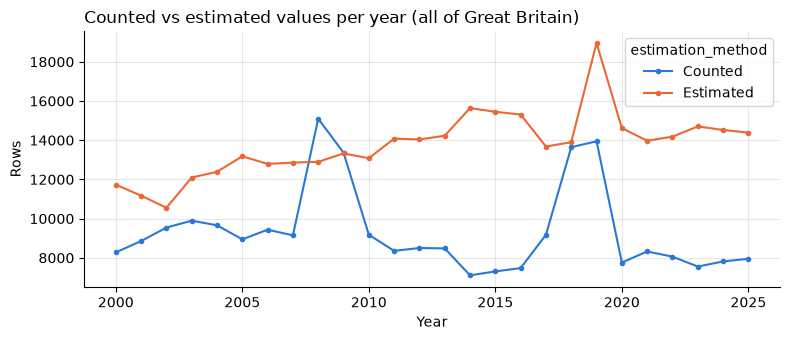

In [7]:
per_year = aadf.groupby(["year", "estimation_method"]).size().unstack()
ax = per_year.plot(figsize=(8, 3.5), marker="o", ms=3, color=[BLUE, "#eb6834"])
ax.set_ylabel("Rows")
ax.set_xlabel("Year")
ax.set_title("Counted vs estimated values per year (all of Great Britain)")
plt.tight_layout()
plt.show()

In [8]:
latest = aadf[aadf["year"] == aadf["year"].max()]
print(f"Counted values by road type in {aadf['year'].max()}:")
print(latest.groupby(["road_type", "estimation_method"]).size().unstack().to_string())

Counted values by road type in 2025:
estimation_method  Counted  Estimated
road_type                            
Major                 4241      13700
Minor                 3709        684


## 4. Joining the two files

In [9]:
ids_aadf, ids_cp = set(aadf["count_point_id"]), set(cp["count_point_id"])
print(f"Count points in AADF file: {len(ids_aadf):,}")
print(f"Count points in count point file: {len(ids_cp):,}")
print(f"In AADF but not in count points: {len(ids_aadf - ids_cp):,}")
print(f"In count points but never in AADF: {len(ids_cp - ids_aadf):,}")

Count points in AADF file: 46,754
Count points in count point file: 46,754
In AADF but not in count points: 0
In count points but never in AADF: 0


- The AADF file already contains the location and road columns, so for the experiments we only need it.

- The count point file is useful as a complete list of locations, including points without recent values.

## 5. Choosing an area

We need an urban area with enough **counted** values in one year to hide some and still test reliably (at least 150-200).

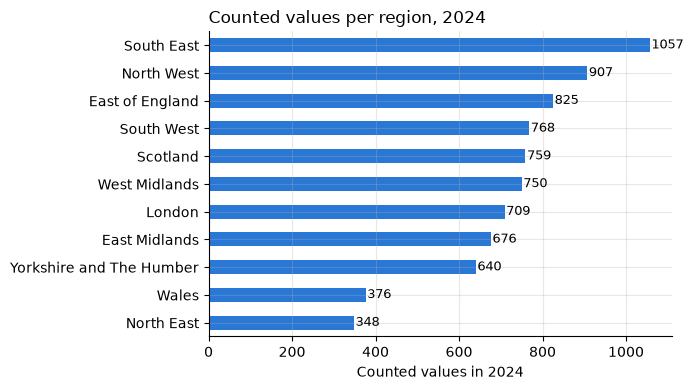

In [10]:
YEAR = 2024
counted = aadf[(aadf["year"] == YEAR) & (aadf["estimation_method"] == "Counted")]
by_region = counted.groupby("region_name").size().sort_values()
ax = by_region.plot.barh(figsize=(7, 4), color=BLUE)
for i, v in enumerate(by_region.values):
    ax.text(v + 4, i, str(v), va="center", fontsize=9)
ax.set_xlabel(f"Counted values in {YEAR}")
ax.set_ylabel("")
ax.set_title(f"Counted values per region, {YEAR}")
plt.tight_layout()
plt.show()

In [11]:
print(f"Most counted values per local authority (city or county), {YEAR}:")
print(counted.groupby("local_authority_name").size().sort_values(ascending=False).head(10).to_string())
print()
for city in ["Leeds", "Birmingham", "Manchester"]:
    n = (counted["local_authority_name"] == city).sum()
    print(f"{city}: {n} counted values in {YEAR}")

Most counted values per local authority (city or county), 2024:
local_authority_name
Hampshire          206
Essex              195
Kent               190
Lancashire         180
Hertfordshire      154
Norfolk            149
Surrey             144
North Yorkshire    134
Devon              128
Derbyshire         128

Leeds: 101 counted values in 2024
Birmingham: 76 counted values in 2024
Manchester: 56 counted values in 2024


Single cities are too small: in 2024, Leeds has 101 counted values, Birmingham 76 and Manchester 56. Counties such as Hampshire have more, but they are mostly rural.

London is not the region with the most counted values (709 in 2024, seventh of eleven). The regions above it, such as the South East, are large mixes of counties, towns and countryside. London is the only region that is one continuous urban area, and 709 is well above our target.

## 6. London in detail

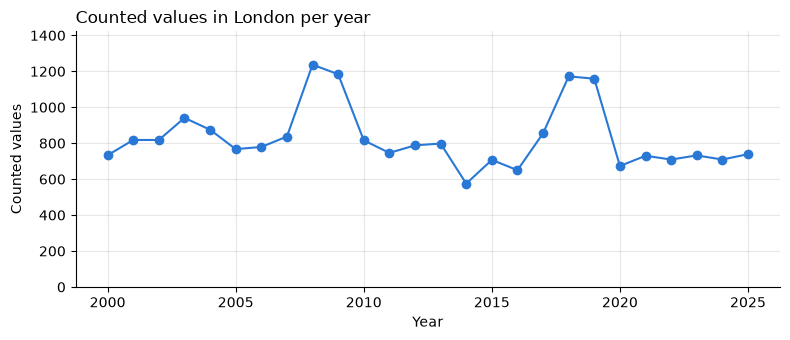

year
2018    1172
2019    1159
2020     673
2021     730
2022     709
2023     732
2024     709
2025     739


In [12]:
lon_all = aadf[aadf["region_name"] == "London"]
lon = lon_all[lon_all["estimation_method"] == "Counted"]
per_year = lon.groupby("year").size()
ax = per_year.plot(figsize=(8, 3.5), marker="o", color=BLUE)
ax.set_ylim(0, per_year.max() * 1.15)
ax.set_xlabel("Year")
ax.set_ylabel("Counted values")
ax.set_title("Counted values in London per year")
plt.tight_layout()
plt.show()
print(per_year.tail(8).to_string())

In [13]:
lon_y = lon[lon["year"] == YEAR]
print(f"Road categories of London's counted points, {YEAR}:")
print(lon_y["road_category"].value_counts().to_string())

Road categories of London's counted points, 2024:
road_category
PA     522
MCU    158
MB      18
TM       8
TA       3


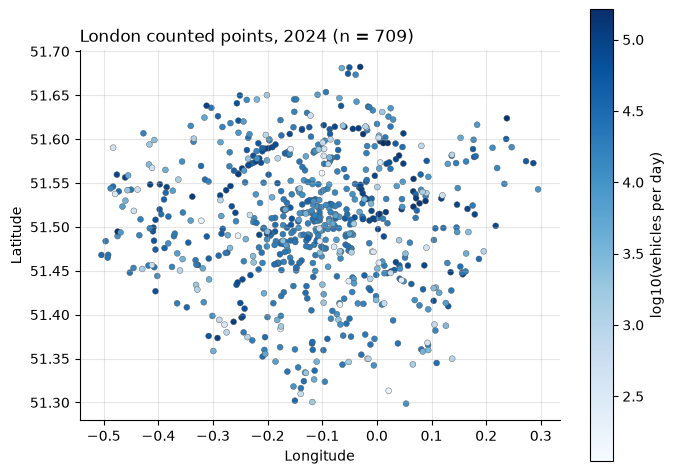

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(lon_y["longitude"], lon_y["latitude"], c=np.log10(lon_y["all_motor_vehicles"]), cmap="Blues", s=18, edgecolors="#52514e", linewidths=0.3)
fig.colorbar(sc, ax=ax).set_label("log10(vehicles per day)")
ax.set_aspect(1 / np.cos(np.radians(51.5)))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"London counted points, {YEAR} (n = {len(lon_y)})")
plt.tight_layout()
plt.show()

### The points are irregular

Distance from each point to its nearest neighbour, using easting/northing (metres). A regular grid would have the same distance everywhere.

Nearest-neighbour distance: median 601m, 10th percentile 195m, 90th percentile 1371m


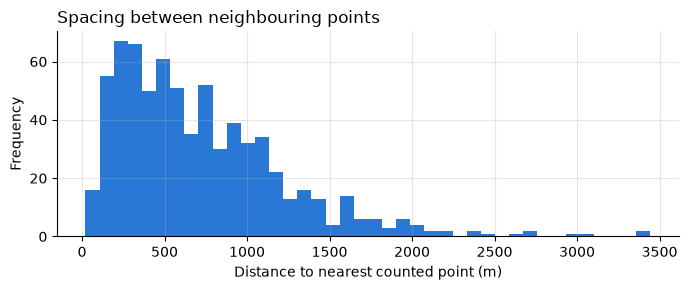

In [15]:
xy = lon_y[["easting", "northing"]].to_numpy(dtype=float)
d, _ = cKDTree(xy).query(xy, k=2)
nn = d[:, 1]
print(f"Nearest-neighbour distance: median {np.median(nn):.0f}m, "
      f"10th percentile {np.percentile(nn, 10):.0f}m, 90th percentile {np.percentile(nn, 90):.0f}m")
ax = pd.Series(nn).plot.hist(bins=40, figsize=(7, 3), color=BLUE)
ax.set_xlabel("Distance to nearest counted point (m)")
ax.set_title("Spacing between neighbouring points")
plt.tight_layout()
plt.show()

### What gridding would do (RQ2)

To use the original VPint, the points must first be put into grid cells. This shows, for several cell sizes, how many cells are empty and how many points end up sharing a cell with another point (and would be averaged together).

In [16]:
rows = []
for size in [250, 500, 1000, 2000]:
    cx = ((xy[:, 0] - xy[:, 0].min()) // size).astype(int)
    cy = ((xy[:, 1] - xy[:, 1].min()) // size).astype(int)
    cells = pd.Series(list(zip(cx, cy))).value_counts()
    total = (cx.max() + 1) * (cy.max() + 1)
    rows.append({"cell size (m)": size, "grid": f"{cx.max()+1} x {cy.max()+1}",
                 "cells with a point": f"{len(cells) / total:.1%}",
                 "points sharing a cell": int(cells[cells > 1].sum()),
                 "max points in one cell": int(cells.max())})
pd.DataFrame(rows)

,cell size (m),grid,cells with a point,points sharing a cell,max points in one cell
0,250,221 x 171,1.8%,32,2
1,500,111 x 86,6.7%,125,5
2,1000,56 x 43,20.8%,342,6
3,2000,28 x 22,47.6%,579,14


### The feature is available for every point

Graph VPint needs a feature at every location. We use the previous year's traffic at the same count point (counted or estimated, since it is only an input).

In [17]:
prev = lon_all[lon_all["year"] == YEAR - 1].set_index("count_point_id")["all_motor_vehicles"]
has_prev = lon_y["count_point_id"].isin(prev.index)
x = prev.loc[lon_y.loc[has_prev, "count_point_id"]].to_numpy()
y = lon_y.loc[has_prev, "all_motor_vehicles"].to_numpy()
r = np.corrcoef(np.log(x), np.log(y))[0, 1]
print(f"{has_prev.sum()} of {len(lon_y)} counted {YEAR} points have a {YEAR-1} value")
print(f"Correlation of log traffic, {YEAR-1} vs {YEAR}: {r:.3f}")

702 of 709 counted 2024 points have a 2023 value
Correlation of log traffic, 2023 vs 2024: 0.995


The correlation is 0.995, so copying last year's value is already an almost perfect estimate. Traffic on a road changes little from year to year, and many 2023 values are themselves estimates carried over from earlier counts.

If we used last year's traffic as the feature, propagation would have almost nothing left to add. So the main experiments use road information as the feature (road category, major or minor), and last year's value only as a reference baseline.

## 7. Conclusion: why London

- **Defined variables:** both files match the DfT metadata document, so every column is documented.
- **Real measurements:** only counted values are actual counts, so the area needs many of them. We hide and test only counted values.
- **Single cities are too small:** Leeds has 101 counted values in 2024, Birmingham 76 and Manchester 56.
- **London is the largest continuous urban area with enough data:** 709 counted values in 2024, and between 673 and 739 every year since 2020 (with peaks of about 1,170 in 2018 and 2019). Regions with more counted values are mostly rural.
- **Urban roads:** 74% of London's counted points are A roads (522 of 709) and 25% are minor roads. Only 11 are motorways or trunk roads.
- **Irregular points:** the distance to the nearest neighbour ranges from under 200m to over 1.3km (median 601m). With 1km grid cells, 342 of the 709 points share a cell with another point and 79% of cells are empty, which is exactly the comparison in RQ2.
- **Features:** every point has a road category. Last year's traffic is available for 702 of 709 points, but it correlates 0.995 with this year's, so we use it only as a reference baseline.